In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, accuracy_score, confusion_matrix
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

df_train = pd.read_csv("data/train_data.csv")
df_test = pd.read_csv("data/test_data.csv")
df_penguins = pd.read_csv("data/penguins_binary_classification.csv")
df_song = pd.read_csv("data/song_data.csv")

# Task 1

In [22]:
target_col = 'age'

feature_cols = df_train.select_dtypes(include=[np.number]).columns.tolist()
feature_cols.remove(target_col)

categorical_cols = df_train.select_dtypes(include=['object', 'bool']).columns.tolist()

if categorical_cols:
    df_train = pd.get_dummies(df_train, columns=categorical_cols, drop_first=True)
    df_test = pd.get_dummies(df_test, columns=categorical_cols, drop_first=True)
    for col in df_train.columns:
        if col not in df_test.columns and col != target_col:
            df_test[col] = 0
    for col in df_test.columns:
        if col not in df_train.columns and col != target_col:
            df_train[col] = 0

feature_cols = [col for col in df_train.columns if col != target_col]

for col in feature_cols + [target_col]:
    if df_train[col].isna().sum() > 0:
        df_train[col] = df_train[col].fillna(df_train[col].median())
    if col in df_test.columns and df_test[col].isna().sum() > 0:
        df_test[col] = df_test[col].fillna(df_train[col].median())

X_train = df_train[feature_cols].values
y_train = df_train[target_col].values
X_test = df_test[feature_cols].values

In [23]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = LinearRegression()
model.fit(X_train_scaled, y_train)

y_train_pred = model.predict(X_train_scaled)
r2_train = r2_score(y_train, y_train_pred)
rmse_train = np.sqrt(mean_squared_error(y_train, y_train_pred))

print(f"R^2 на обучении: {r2_train:.4f}")
print(f"RMSE на обучении: {rmse_train:.2f}")

R^2 на обучении: 0.9867
RMSE на обучении: 1750.65


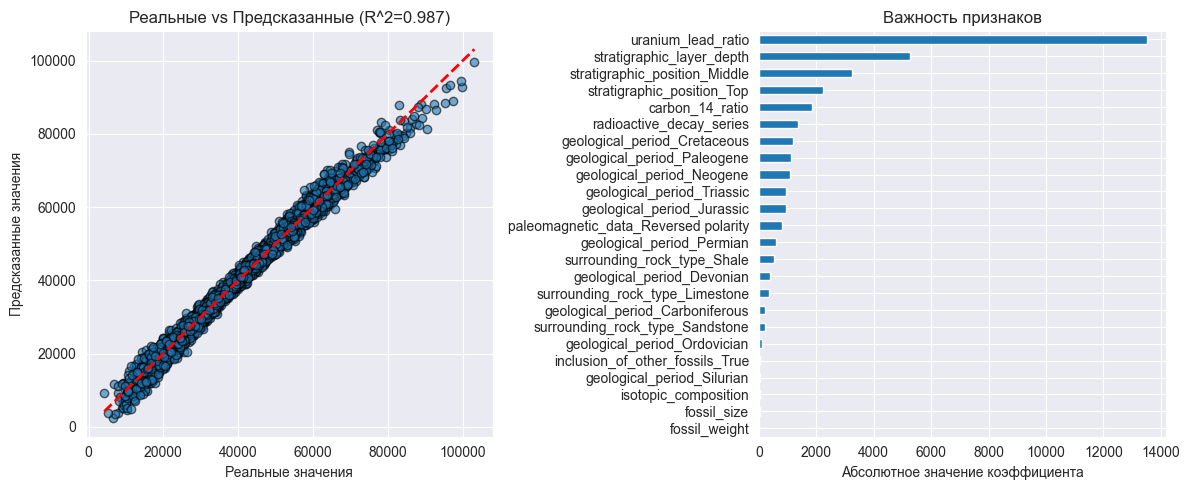

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(y_train, y_train_pred, alpha=0.6, edgecolors='k')
axes[0].plot([y_train.min(), y_train.max()], [y_train.min(), y_train.max()], 'r--', lw=2)
axes[0].set_xlabel('Реальные значения')
axes[0].set_ylabel('Предсказанные значения')
axes[0].set_title(f'Реальные vs Предсказанные (R^2={r2_train:.3f})')

coef_series = pd.Series(model.coef_, index=feature_cols)
coef_series.abs().sort_values().plot(kind='barh', ax=axes[1])
axes[1].set_xlabel('Абсолютное значение коэффициента')
axes[1].set_title('Важность признаков')

plt.tight_layout()
plt.show()

In [25]:
test_predictions = model.predict(X_test_scaled)
print(f"Предсказания на тестовых данных: min={test_predictions.min():.2f}, max={test_predictions.max():.2f}, mean={test_predictions.mean():.2f}")

np.random.seed(42)
n_new = 10
new_data = {}

for col in feature_cols:
    mean_val = df_train[col].mean()
    std_val = df_train[col].std()
    new_data[col] = np.random.normal(mean_val, std_val, n_new)
    if col in ['stratigraphic_layer_depth', 'fossil_size', 'fossil_weight',
               'uranium_lead_ratio', 'carbon_14_ratio', 'radioactive_decay_series', 'isotopic_composition']:
        new_data[col] = np.abs(new_data[col])

new_df = pd.DataFrame(new_data)
new_scaled = scaler.transform(new_df.values)
new_predictions = model.predict(new_scaled)

new_df['predicted_age'] = new_predictions
print(new_df.round(2))

Предсказания на тестовых данных: min=849.22, max=90834.85, mean=41190.78
   uranium_lead_ratio  carbon_14_ratio  radioactive_decay_series  \
0                0.61             0.32                      0.95   
1                0.45             0.32                      0.47   
2                0.65             0.49                      0.55   
3                0.88             0.02                      0.12   
4                0.43             0.03                      0.38   
5                0.43             0.30                      0.56   
6                0.89             0.19                      0.20   
7                0.68             0.50                      0.64   
8                0.37             0.22                      0.36   
9                0.63             0.10                      0.45   

   stratigraphic_layer_depth  isotopic_composition  fossil_size  \
0                     100.92                  1.32        82.81   
1                     312.63                

# Task 2

In [26]:
df_penguins['target'] = (df_penguins['species'] == 'Adelie').astype(int)

num_features = df_penguins.select_dtypes(include=[np.number]).columns.tolist()
if 'target' in num_features:
    num_features.remove('target')

for col in num_features:
    if df_penguins[col].isna().sum() > 0:
        df_penguins[col] = df_penguins[col].fillna(df_penguins[col].median())

X = df_penguins[num_features].values
y = df_penguins['target'].values

scaler_peng = StandardScaler()
X_scaled = scaler_peng.fit_transform(X)

split_idx = int(0.8 * len(X_scaled))
X_train, X_test = X_scaled[:split_idx], X_scaled[split_idx:]
y_train, y_test = y[:split_idx], y[split_idx:]

In [27]:
log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train, y_train)

y_pred = log_reg.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f"Точность модели: {accuracy:.4f}")

cm = confusion_matrix(y_test, y_pred)
print("Матрица ошибок:")
if cm.shape == (1, 1):
    print(f"  [[{cm[0][0]}]]")
    print("  (В тестовой выборке представлен только один класс)")
else:
    print(pd.DataFrame(cm, columns=['Pred 0', 'Pred 1'], index=['True 0', 'True 1']))

Точность модели: 1.0000
Матрица ошибок:
  [[55]]
  (В тестовой выборке представлен только один класс)


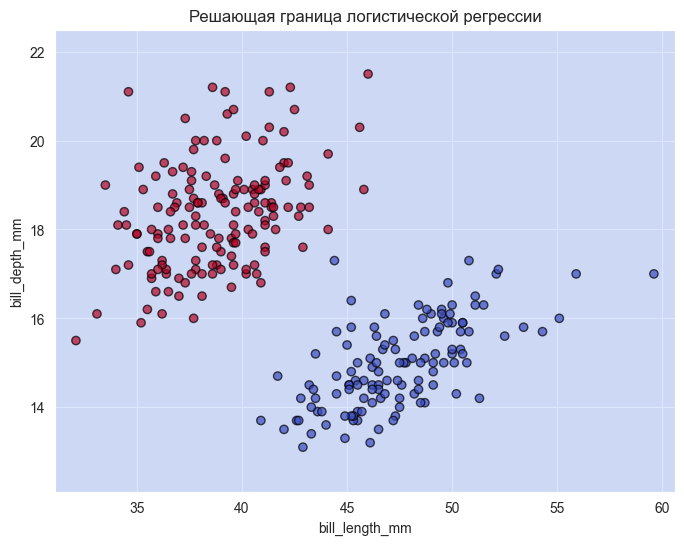

In [28]:
feature1, feature2 = num_features[0], num_features[1]

x_min, x_max = df_penguins[feature1].min() - 1, df_penguins[feature1].max() + 1
y_min, y_max = df_penguins[feature2].min() - 1, df_penguins[feature2].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 100), np.linspace(y_min, y_max, 100))

grid_input = np.c_[xx.ravel(), yy.ravel()]
for _ in range(len(num_features) - 2):
    grid_input = np.c_[grid_input, np.zeros(grid_input.shape[0])]
grid_scaled = scaler_peng.transform(grid_input)

Z = log_reg.predict(grid_scaled).reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
plt.scatter(df_penguins[feature1], df_penguins[feature2], c=df_penguins['target'],
            cmap='coolwarm', edgecolors='k', alpha=0.7)
plt.xlabel(feature1)
plt.ylabel(feature2)
plt.title('Решающая граница логистической регрессии')
plt.show()

# Task ****

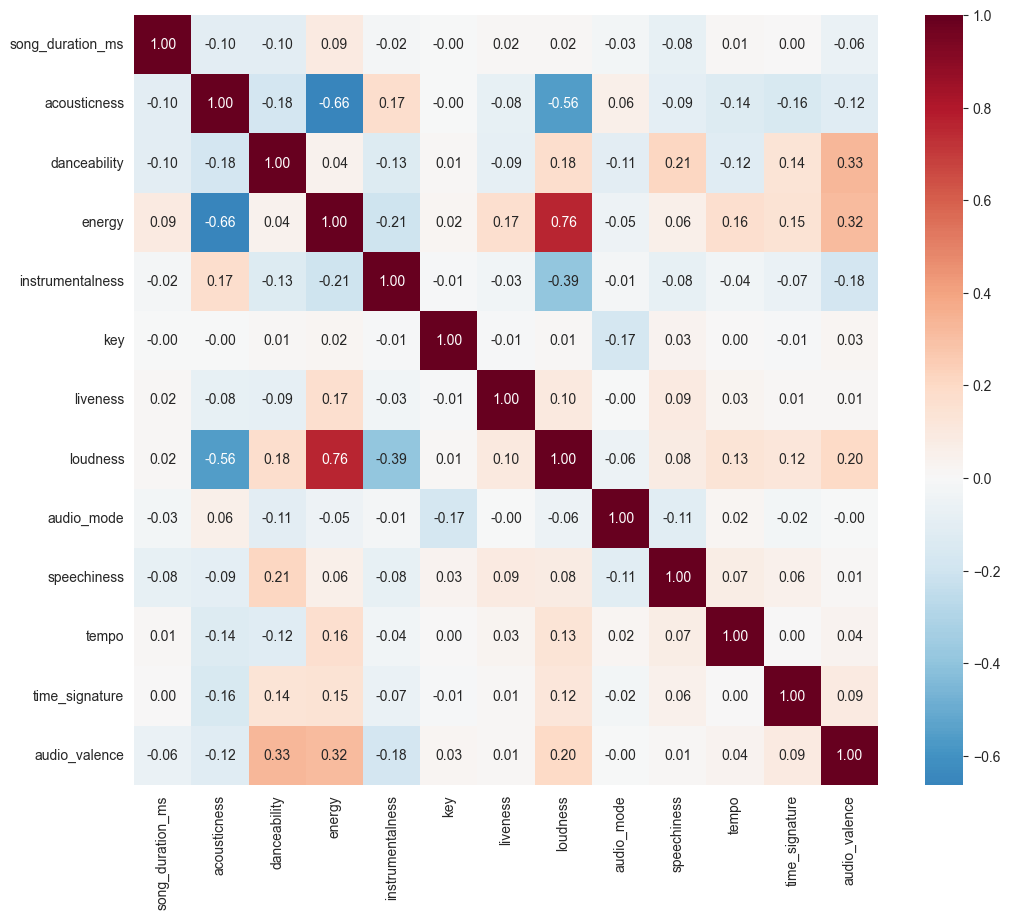

In [29]:
target = 'song_popularity'
num_cols = df_song.select_dtypes(include=[np.number]).columns.tolist()
num_cols.remove(target)

for col in num_cols + [target]:
    if df_song[col].isna().sum() > 0:
        df_song[col] = df_song[col].fillna(df_song[col].median())

plt.figure(figsize=(12,10))
sns.heatmap(df_song[num_cols].corr(), annot=True, cmap='RdBu_r', center=0, fmt='.2f')
plt.show()

from sklearn.preprocessing import StandardScaler
X_temp = StandardScaler().fit_transform(df_song[num_cols])
vif_list = []
for i in range(len(num_cols)):
    X_other = X_temp[:, [j for j in range(len(num_cols)) if j != i]]
    _, residuals, _, _ = np.linalg.lstsq(X_other, X_temp[:, i], rcond=None)
    r2_i = 1 - residuals[0] / np.var(X_temp[:, i])
    vif = 1 / (1 - r2_i)
    vif_list.append(vif)

bad_feats = [num_cols[i] for i, v in enumerate(vif_list) if v > 10]
good_feats = [f for f in num_cols if f not in bad_feats]

In [35]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

vif_data = pd.DataFrame()
vif_data['Признак'] = num_cols
vif_data['VIF'] = [variance_inflation_factor(X_temp, i) for i in range(X_temp.shape[1])]
vif_data = vif_data.sort_values('VIF', ascending=False)

print(vif_data.round(2).to_string(index=False))
print(f"\nУдалено признаков с VIF>10: {len(bad_feats)}")
print(f"Оставлено признаков: {len(good_feats)}")

X = df_song[good_feats].values
y = df_song[target].values

scaler = StandardScaler()
X = scaler.fit_transform(X)

split = int(0.8 * len(X))
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

lr = LinearRegression()
lr.fit(X_train, y_train)
ridge = Ridge(alpha=1.0)
ridge.fit(X_train, y_train)
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

print("\nСравнение моделей")
print("{:<12} R^2    RMSE   MAE".format("Модель"))

for name, model in [("Linear", lr), ("Ridge", ridge), ("RandomForest", rf)]:
    y_pred = model.predict(X_test)
    r2 = r2_score(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)
    print("{:<12} {:.4f}  {:.2f}   {:.2f}".format(name, r2, rmse, mae))


# На паре сказали что это норм, нужно загрузить как будет доступ в СДО - вы актуализируете оценку

         Признак  VIF
          energy 3.73
        loudness 2.94
    acousticness 1.98
    danceability 1.43
   audio_valence 1.39
instrumentalness 1.25
     speechiness 1.10
           tempo 1.06
      audio_mode 1.06
        liveness 1.05
  time_signature 1.05
song_duration_ms 1.05
             key 1.03

Удалено признаков с VIF>10: 0
Оставлено признаков: 13

Сравнение моделей
Модель       R^2    RMSE   MAE
Linear       0.0456  22.00   17.51
Ridge        0.0456  22.00   17.51
RandomForest 0.4528  16.66   11.54
